In [1]:
import iblatlas.genomics.merfish as mf

In [2]:
df_cells, df_classes, df_subclasses, df_supertypes, df_clusters, df_genes, df_nt = mf.load(folder_cache="./")
df_cells

,brain_section_label,donor_label,neurotransmitter,class,subclass,supertype,cluster,x,y,z,Allen_id
cell_label,,,,,,,,,,,
1019171907102340387-1,C57BL6J-638850.37,C57BL6J-638850,<NA>,4,38,141,515,0.001716,-0.002095,-0.002114,10704
1104095349101460194-1,C57BL6J-638850.26,C57BL6J-638850,Glut,23,235,953,4199,-0.000514,-0.003828,-0.005802,574
1017092617101450577,C57BL6J-638850.25,C57BL6J-638850,Glut,23,235,953,4199,0.000264,-0.003945,-0.006658,771
1018093344101130233,C57BL6J-638850.13,C57BL6J-638850,Glut,23,235,953,4199,-0.002434,-0.005577,-0.004067,728
1019171912201610094,C57BL6J-638850.27,C57BL6J-638850,Glut,23,235,953,4199,0.000088,-0.003597,-0.006466,771
...,...,...,...,...,...,...,...,...,...,...,...
207078638049612663505414491993744973724,Zhuang-ABCA-4.001,Zhuang-ABCA-4,<NA>,34,334,1194,5312,-0.003980,0.001446,-0.003479,0
269688622729976403473132483008812650057,Zhuang-ABCA-4.001,Zhuang-ABCA-4,<NA>,34,334,1194,5312,-0.003976,0.001444,-0.003361,878
32317399564312907213846667957826182632,Zhuang-ABCA-4.001,Zhuang-ABCA-4,<NA>,33,333,1193,5310,-0.003973,0.001426,-0.003269,878


In [3]:
import scanpy as sc

adata = sc.read_h5ad("merfish/C57BL6J-638850-raw.h5ad")
adata

AnnData object with n_obs × n_vars = 4334174 × 550
    obs: 'brain_section_label'
    var: 'gene_symbol', 'transcript_identifier'
    uns: 'accessed_on', 'src'

In [5]:
import pandas as pd

df_filtered = df_cells[df_cells["donor_label"] == "C57BL6J-638850"]
df_aligned = df_filtered.reindex(adata.obs.index)
adata.obs[df_aligned.columns] = df_aligned

In [6]:
adata = adata[adata.obs["Allen_id"].notna()].copy()
adata.X.shape

(3477817, 550)

In [7]:
adata.obs

,brain_section_label,donor_label,neurotransmitter,class,subclass,supertype,cluster,x,y,z,Allen_id
cell_label,,,,,,,,,,,
1019171911101460569,C57BL6J-638850.05,C57BL6J-638850,Glut,23.0,235.0,953.0,4199.0,0.001647,-0.006882,-0.006656,955.0
1019171911101550321,C57BL6J-638850.05,C57BL6J-638850,Glut,23.0,235.0,953.0,4199.0,-0.001372,-0.006792,-0.006670,955.0
1019171911100841066,C57BL6J-638850.05,C57BL6J-638850,Glut,23.0,235.0,953.0,4199.0,0.001336,-0.007100,-0.004418,903.0
1019171911101400425,C57BL6J-638850.05,C57BL6J-638850,Chol,24.0,261.0,1027.0,4603.0,-0.001610,-0.006832,-0.006213,852.0
1019171911101380264,C57BL6J-638850.05,C57BL6J-638850,Glut,23.0,235.0,953.0,4199.0,-0.002791,-0.006839,-0.005804,0.0
...,...,...,...,...,...,...,...,...,...,...,...
1017201423100590639,C57BL6J-638850.67,C57BL6J-638850,<NA>,33.0,333.0,1193.0,5309.0,-0.000574,0.005156,-0.005115,1016.0
1017201423100550444,C57BL6J-638850.67,C57BL6J-638850,<NA>,33.0,333.0,1193.0,5309.0,-0.000571,0.004953,-0.003118,507.0
1017201423100460203-1,C57BL6J-638850.67,C57BL6J-638850,<NA>,33.0,333.0,1193.0,5309.0,-0.000203,0.004921,-0.002912,507.0


In [7]:
from iblatlas.regions import BrainRegions
import pandas as pd

br = BrainRegions()

region_table = pd.DataFrame({
    'atlas_id': br.id,
    'acronym': br.acronym,
    'name': br.name,
    'level': br.level,
    'parent': br.parent,
    'order': br.order
})

region_table[:]

,atlas_id,acronym,name,level,parent,order
0,0,void,void,0,NaN,0
1,997,root,root,0,NaN,0
2,8,grey,Basic cell groups and regions,1,997.0,1
3,567,CH,Cerebrum,2,8.0,2
4,688,CTX,Cerebral cortex,3,567.0,3
...,...,...,...,...,...,...
2650,-49,ipf,intraparafloccular fissure (left),3,-1040.0,1322
2651,-57,pms,paramedian sulcus (left),3,-1040.0,1323
2652,-65,pfs,parafloccular sulcus (left),3,-1040.0,1324
2653,-624,IPF,Interpeduncular fossa (left),2,-1024.0,1325


In [8]:
import numpy as np
from collections import defaultdict, deque

region_table['parent'] = region_table['parent'].replace({None: np.nan})

id_to_acronym = dict(zip(region_table['atlas_id'], region_table['acronym']))
acronym_to_id = dict(zip(region_table['acronym'], region_table['atlas_id']))

children_map = defaultdict(list)
for _, row in region_table.iterrows():
    pid = row['parent']
    child_id = row['atlas_id']
    if not pd.isna(pid):
        children_map[int(pid)].append(int(child_id))

def get_descendant_acronyms(parent_acronym):

    if parent_acronym not in acronym_to_id:
        return []
    root_id = int(acronym_to_id[parent_acronym])
    descendants = []

    dq = deque([root_id])
    while dq:
        cur = dq.popleft()
        if cur in id_to_acronym:
            descendants.append(id_to_acronym[cur])
        for child in children_map.get(cur, []):
            dq.append(child)
    return descendants


df_nolayers = pd.read_csv("../BWM/result/wo_layer/stage1/df_scaled.csv", index_col=0)
target_parents = list(df_nolayers.index.astype(str).tolist())

missing_parents = []
all_target_acronyms = set()
for p in target_parents:
    desc = get_descendant_acronyms(p)
    if len(desc) == 0:
        missing_parents.append(p)
    else:
        all_target_acronyms.update(desc)

if missing_parents:
    print("The following brain regions in df_layers were not found in the region_table (check names or case):")
    for mp in missing_parents:
        print("  -", mp)

print(f"{len(all_target_acronyms)} brain regions will be retained (including the parent region of df_nolayers and all its child regions).")

map_child_to_parent = {}
for parent in target_parents:
    for child in get_descendant_acronyms(parent):
        map_child_to_parent[child] = parent

###############################################

###############################################

acr_to_parent = pd.Series(map_child_to_parent)

id_to_acr = region_table.set_index("atlas_id")["acronym"]

allen_id = adata.obs["Allen_id"].astype("float").astype("Int64")
acr = allen_id.map(id_to_acr)   

acr_filtered = acr.where(acr.isin(all_target_acronyms))

adata.obs["parent_key"] = acr_filtered.map(acr_to_parent)

483 brain regions will be retained (including the parent region of df_nolayers and all its child regions).


In [9]:
adata = adata[adata.obs["parent_key"].notna()].copy()
adata.obs

,brain_section_label,donor_label,neurotransmitter,class,subclass,supertype,cluster,x,y,z,Allen_id,parent_key
cell_label,,,,,,,,,,,,
1018093343101250153,C57BL6J-638850.14,C57BL6J-638850,GABA-Glyc,28.0,308.0,1141.0,5167.0,-0.001134,-0.005450,-0.003910,867.0,PB
1018093343101100492,C57BL6J-638850.14,C57BL6J-638850,GABA,28.0,309.0,1147.0,5185.0,-0.001283,-0.005455,-0.003815,867.0,PB
1018093343101720859,C57BL6J-638850.14,C57BL6J-638850,GABA,28.0,312.0,1151.0,5192.0,0.000945,-0.005529,-0.003732,867.0,PB
1018093343101260154,C57BL6J-638850.14,C57BL6J-638850,GABA,28.0,311.0,1149.0,5188.0,-0.000997,-0.005485,-0.003607,867.0,PB
1018093343101250243,C57BL6J-638850.14,C57BL6J-638850,Glut,29.0,315.0,1156.0,5205.0,-0.001064,-0.005453,-0.003901,867.0,PB
...,...,...,...,...,...,...,...,...,...,...,...,...
1017185048100450487,C57BL6J-638850.62,C57BL6J-638850,<NA>,33.0,333.0,1193.0,5309.0,-0.000842,0.003128,-0.002890,288.0,ORBvl
1017185048100310427,C57BL6J-638850.62,C57BL6J-638850,<NA>,33.0,333.0,1193.0,5309.0,-0.001495,0.003154,-0.002959,412.0,ORBl
1017185048100840224,C57BL6J-638850.62,C57BL6J-638850,<NA>,33.0,333.0,1193.0,5309.0,0.000131,0.003139,-0.003288,484.0,ORBm


In [11]:
import pandas as pd
import numpy as np
import scipy.sparse as sp

groups = adata.obs["parent_key"]

X = adata.X
if sp.issparse(X):
    X = X.toarray()

df_expr = pd.DataFrame(X, index=adata.obs_names, columns=adata.var_names)
df_expr["parent_key"] = groups.values

df_mean = df_expr.groupby("parent_key").mean()

df_mean.columns = adata.var.loc[df_mean.columns, "gene_symbol"].values
df_mean.index.name = None

df_mean

,Prkcq,Col5a1,Grik3,Igfbp2,Osr1,Syt6,Cntnap3,Lmo3,Ntn1,Otp,...,Blank-16,Blank-32,Blank-18,Blank-4,Blank-28,Blank-33,Blank-34,Blank-45,Blank-23,Blank-48
AAA,0.688320,0.419738,3.770352,1.059754,0.415574,1.491568,0.966479,1.546950,0.978555,0.237768,...,0.029981,0.094732,0.023319,0.062877,0.028316,0.067458,0.069123,0.029565,0.026858,0.024776
ACAd,0.402855,1.987239,8.345952,2.284560,0.310034,2.700222,0.789593,1.220095,0.731178,0.090411,...,0.028026,0.136727,0.020984,0.051278,0.062196,0.034642,0.470438,0.059502,0.142398,0.026844
ACAv,0.328687,2.627264,8.641244,1.320250,0.250393,2.375589,0.842791,1.321367,0.477417,0.091778,...,0.026967,0.124204,0.020887,0.050666,0.055464,0.029738,0.440731,0.055629,0.131525,0.027463
ACB,0.499769,0.368579,4.516767,0.529868,0.199354,9.115001,2.756089,1.624091,2.828264,0.064960,...,0.030128,0.179499,0.027935,0.064152,0.030388,0.074657,0.092549,0.092462,0.045567,0.044730
AId,0.356029,1.793423,7.794414,3.391010,0.337575,1.420206,1.199196,1.628216,0.936264,0.082631,...,0.026332,0.144219,0.022476,0.057732,0.061973,0.038506,0.617969,0.080758,0.144163,0.025946
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
VM,0.784140,0.065440,0.800727,0.874347,0.109521,0.237900,0.204272,0.119746,0.493297,0.116792,...,0.017042,0.087480,0.015224,0.042263,0.007498,0.019995,0.059759,0.014769,0.019995,0.014088
VPL,0.842526,0.085474,0.524421,2.024211,0.157263,0.154316,0.105474,0.062947,0.509263,0.058316,...,0.013474,0.126316,0.015579,0.035789,0.013263,0.017684,0.127789,0.014947,0.016000,0.021053
VPLpc,0.611314,0.067518,0.901460,1.270073,0.125912,0.160584,0.118613,0.058394,0.434307,0.051095,...,0.010949,0.045620,0.014599,0.023723,0.009124,0.003650,0.091241,0.007299,0.020073,0.020073
VPM,0.553974,0.079852,0.383734,3.496303,0.281608,0.105730,0.066821,0.056932,0.536414,0.053604,...,0.012477,0.151571,0.013401,0.037616,0.015250,0.015619,0.141959,0.017283,0.017190,0.023752


In [12]:
df_mean.to_csv("merfish/merfish_group_by_region.csv")

In [14]:
count_table = (
    adata.obs.groupby("parent_key")["neurotransmitter"]
    .value_counts(normalize=True)
    .unstack(fill_value=0)
)

count_table.index.name = None


count_table

neurotransmitter,Chol,Dopa,GABA,GABA-Glyc,Glut,Glut-GABA,Nora,Sero
AAA,0.026902,0.0,0.736864,0.00042,0.23161,0.004203,0.0,0.0
ACAd,0.0,0.0,0.11846,0.0,0.88099,0.00055,0.0,0.0
ACAv,0.0,0.0,0.09172,0.0,0.90789,0.00039,0.0,0.0
ACB,0.007831,0.0,0.986176,0.0,0.004522,0.001471,0.0,0.0
AId,0.0,0.0,0.132951,0.0,0.866645,0.000404,0.0,0.0
...,...,...,...,...,...,...,...,...
VM,0.0,0.0,0.040731,0.000522,0.958747,0.0,0.0,0.0
VPL,0.0,0.0,0.055556,0.0,0.944444,0.0,0.0,0.0
VPLpc,0.0,0.0,0.017182,0.0,0.982818,0.0,0.0,0.0
VPM,0.0,0.0,0.005398,0.0,0.994602,0.0,0.0,0.0


In [15]:
count_table.to_csv("./merfish/neurotransmitter_fraction.csv")

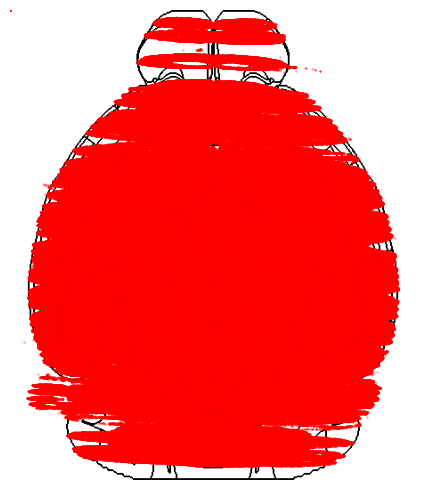

In [17]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25)

x_vals = adata.obs['x'] * 1e6
y_vals = adata.obs['y'] * 1e6
z_vals = adata.obs['z'] * 1e6

dv_coordinate = -3500 / 1e6

fig, ax = plt.subplots(figsize=(5, 5))
atlas.plot_hslice(dv_coordinate, volume='boundary', ax=ax)

ax.scatter(
    x_vals,
    y_vals,
    c='red',
    s=0.1,
    alpha=0.7
)

#ax.set_xlabel("ML (x, μm)")
#ax.set_ylabel("AP (y, μm)")

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.savefig("./slice_plot.tiff", dpi=600, bbox_inches="tight")
plt.show()

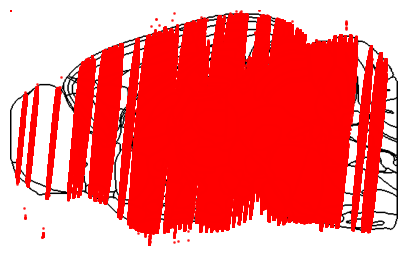

In [22]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas

atlas = AllenAtlas(res_um=25)

x_vals = adata.obs['x'] * 1e6 
y_vals = adata.obs['y'] * 1e6 
z_vals = adata.obs['z'] * 1e6 

ml_coordinate = -800 / 1e6  
fig, ax = plt.subplots(figsize=(5, 5))
atlas.plot_sslice(ml_coordinate, volume='boundary', ax=ax)

ax.scatter(y_vals, z_vals, c='red', s=1, alpha=0.7)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks([])
ax.set_yticks([])

#ax.set_xlabel("AP (y, um)")
#ax.set_ylabel("DV (z, um)")
#ax.legend()
plt.savefig("./slice_plot2.tiff", format="tif", dpi=600, bbox_inches="tight")
plt.show()